# MIL-STD-188-110C serial tone, block by block

This notebook follows one message through the modem: Figure 2 of the standard on the
transmit side, then an HF channel, then the receiver. Every step calls the same code that
`m110c-tx`, `m110c-chan` and `m110c-rx` use, so what is plotted is what the tools do.

It is generated from `docs/walkthrough.py` (`python tools/build_notebook.py`), and that
script is run by the test suite, so the two cannot drift apart. Paragraph numbers refer to
MIL-STD-188-110C; "INT-nnn" to the interpretations in `docs/SPEC_NOTES.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from nbtools import QUICK

from m110c import fec, scrambler, symbols
from m110c.bits import bits_to_bytes, bytes_to_bits
from m110c.channel.watterson import ChannelSpec, WattersonChannel
from m110c.interleave import permutation
from m110c.modulate import modulate, rrc_taps
from m110c.rx.acquire import PreambleSearch
from m110c.rx.decode import DataDecoder
from m110c.rx.eom import EomDetector
from m110c.rx.equalize import EqualizingDemodulator
from m110c.spec import mode
from m110c.spec import tables as T
from m110c.tx import transmit, transmit_bytes

plt.rcParams["figure.figsize"] = (8, 3)
MODE = mode(2400, "short")  # 2400 bps, 0.6-s interleaver
MESSAGE = b"THE QUICK BROWN FOX JUMPS OVER THE LAZY DOG 0123456789\r\n" * 4
print(MODE, "-", len(MESSAGE), "bytes")

2400S - 224 bytes


## 1. Bytes to bits

The standard carries a synchronous bit stream (§4.2.3). Bytes go least significant bit
first, the UART convention, which the real recordings confirmed (INT-016). With
`--async 8N1` each byte also gets a start and a stop bit (INT-025).

In [2]:
user_bits = bytes_to_bits(MESSAGE)
print("'T' = 0x54 ->", user_bits[:8])

'T' = 0x54 -> [0 0 1 0 1 0 1 0]


## 2. Forward error correction (§5.3.2.3.3)

A rate-1/2, constraint-length-7 convolutional code: each input bit gives two coded bits
from two generator polynomials (T1 = x⁶+x⁴+x³+x+1, T2 = x⁶+x⁵+x⁴+x³+1). At 150 and 300 bps
the coded pairs are then repeated (INT-008). The receiver undoes this with a soft-decision
Viterbi decoder.

In [3]:
coded = fec.ConvolutionalEncoder().encode(user_bits)
print(len(user_bits), "bits ->", len(coded), "coded bits; first 16:", coded[:16])

1792 bits -> 3584 coded bits; first 16: [0 0 0 0 1 1 0 1 0 0 1 0 0 0 0 0]


## 3. Interleaving (§5.3.2.3.4)

A block interleaver spreads each burst of channel errors over many code words. Bits are
loaded down the rows of a matrix, stepping the row by 9 (by 7 at 75 bps, INT-007), and
fetched along diagonals. The plot shows where each input bit of one block ends up: a
fade that wipes out neighbouring channel bits hits bits far apart in the code.

block: 40 x 72 = 2880 bits


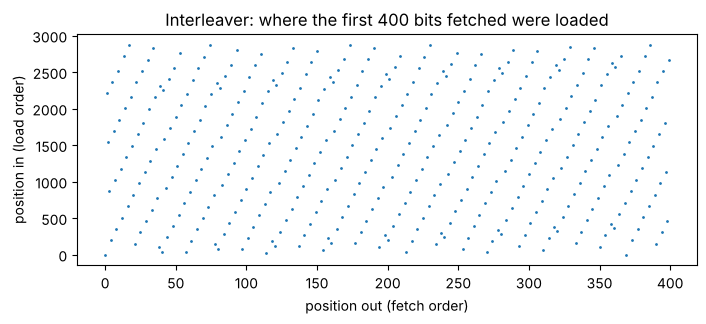

In [4]:
perm = permutation(MODE)
print("block:", MODE.interleaver_rows, "x", MODE.interleaver_cols, "=", perm.size, "bits")
plt.plot(perm[:400], ".", markersize=2)
plt.xlabel("position out (fetch order)")
plt.ylabel("position in (load order)")
plt.title("Interleaver: where the first 400 bits fetched were loaded")
plt.show()

What that buys. A fade wipes out a run of consecutive channel bits: here 60 of them, 20
symbols or about 8 ms at 2400 bps. After deinterleaving, the same 60 errors are scattered
across the block, far apart in the coded stream. The Viterbi decoder corrects isolated
errors well and bursts badly: its memory (constraint length 7) spans only a few bits.

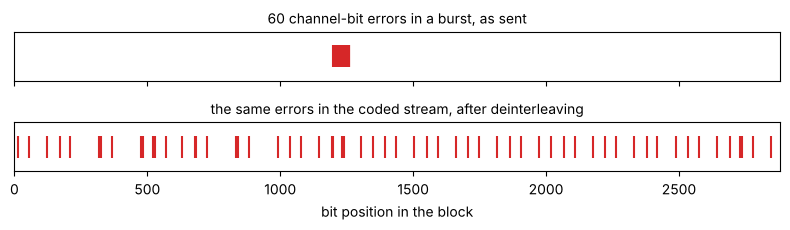

after deinterleaving, the closest two errors are 7 bits apart


In [5]:
burst = np.arange(1200, 1260)  # 60 consecutive bits as sent
in_code = np.sort(perm[burst])  # where they sit in the coded stream
fig, ax = plt.subplots(2, 1, figsize=(8, 2.4), sharex=True)
ax[0].eventplot(burst, colors="C3")
ax[0].set_title("60 channel-bit errors in a burst, as sent", fontsize=10)
ax[1].eventplot(in_code, colors="C3")
ax[1].set_title("the same errors in the coded stream, after deinterleaving", fontsize=10)
for a in ax:
    a.set_yticks([])
ax[1].set_xlim(0, perm.size)
ax[1].set_xlabel("bit position in the block")
plt.tight_layout()
plt.show()
print("after deinterleaving, the closest two errors are", np.diff(in_code).min(), "bits apart")

## 4. Symbol formation, scrambling and framing (§5.3.2.3.6–8)

At 2400 bps every three interleaved bits pick one of eight phases, through a modified
Gray code (MGD, INT-020). Data frames alternate 32 unknown (data) symbols with 16 known
probe symbols, which the receiver uses to measure the channel. A pseudo-random sequence
then scrambles every symbol (Figure 6, INT-003), so even a run of zeros spreads over all
eight phases.

preamble 1440 symbols ( 0.6 s ), data phase 2880 symbols


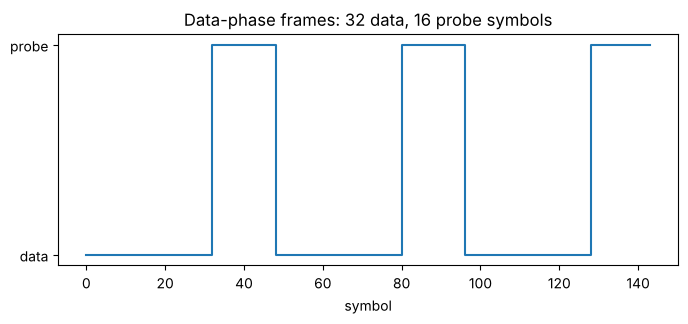

In [6]:
tx = transmit_bytes(MESSAGE, MODE)  # the whole chain, as m110c-tx runs it
n_pre = symbols.preamble_tribits(MODE).size
print("preamble", n_pre, "symbols (", n_pre / 2400, "s ), data phase", tx.size - n_pre, "symbols")
frame = np.r_[np.zeros(MODE.unknown_per_frame), np.ones(MODE.known_per_frame)]
plt.step(np.arange(3 * frame.size), np.tile(frame, 3), where="post")
plt.yticks([0, 1], ["data", "probe"])
plt.xlabel("symbol")
plt.title("Data-phase frames: 32 data, 16 probe symbols")
plt.show()

### The constellations and their bit labels

Each rate uses a subset of the eight phases (Figure 5, INT-020): two at 600-150 bps, four
at 1200 bps, all eight at 2400 and 4800 bps. The labels are the channel bits that pick each
phase, after the MGD. Neighbouring phases differ in exactly one bit, so the commonest
error, mistaking a phase for its neighbour, costs one bit (§5.3.2.3.6 note).

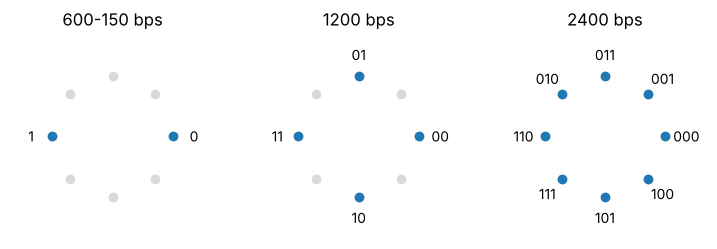

bits that differ between neighbouring phases at 2400 bps: [1, 1, 1, 1, 1, 1, 1, 1]


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(9, 3.2))
for a, (n, rates) in zip(ax, ((1, "600-150 bps"), (2, "1200 bps"), (3, "2400 bps")), strict=True):
    circle = np.exp(1j * np.pi / 4 * np.arange(8))
    a.plot(circle.real, circle.imag, "o", color="0.85")
    for tribit, bits in symbols.tribit_labels(n).items():
        p = np.exp(1j * np.pi / 4 * tribit)
        a.plot(p.real, p.imag, "o", color="C0")
        a.annotate(
            "".join(map(str, bits)),
            (p.real, p.imag),
            xytext=(1.35 * p.real, 1.35 * p.imag),
            ha="center",
            va="center",
        )
    a.set_title(rates)
    a.set_xlim(-1.7, 1.7)
    a.set_ylim(-1.7, 1.7)
    a.set_aspect("equal")
    a.axis("off")
plt.show()
labels = symbols.tribit_labels(3)
neighbours = [
    sum(x != y for x, y in zip(labels[k], labels[(k + 1) % 8], strict=True)) for k in range(8)
]
print("bits that differ between neighbouring phases at 2400 bps:", neighbours)

### Why scramble

Without the scrambler, a message of zeros would send phase 0 almost all the time: nearly
a single tone at 1800 Hz (the D1/D2 probes add a little else). A tone tells the receiver
nothing about the channel at other frequencies, and one fade can null it entirely.
Scrambled (Figure 6), the same message fills the 300-3300 Hz band like any other.

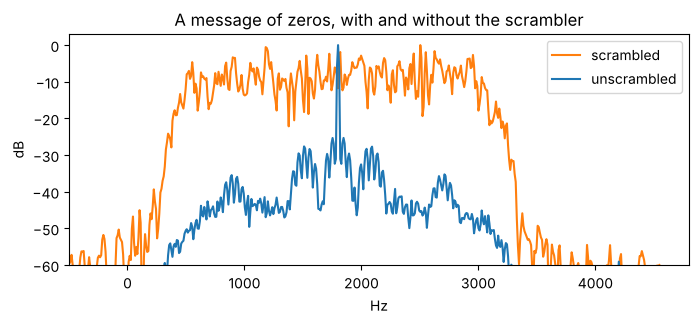

In [8]:
zeros = transmit_bytes(bytes(1200), MODE)[n_pre:]
plain = (zeros.astype(int) - scrambler.data_sequence(0, zeros.size)) % 8  # undo it
n_fft = 1024
freqs = np.fft.fftshift(np.fft.fftfreq(n_fft, 1 / 9600))
for tribits, label, colour in ((zeros, "scrambled", "C1"), (plain, "unscrambled", "C0")):
    sig = modulate(tribits.astype(np.uint8))
    seg = sig[: sig.size // n_fft * n_fft].reshape(-1, n_fft) * np.hanning(n_fft)
    spec = np.fft.fftshift(np.mean(np.abs(np.fft.fft(seg, axis=1)) ** 2, axis=0))
    plt.plot(freqs, 10 * np.log10(spec / spec.max()), color=colour, label=label)
plt.xlim(-500, 4800)
plt.ylim(-60, 3)
plt.xlabel("Hz")
plt.ylabel("dB")
plt.title("A message of zeros, with and without the scrambler")
plt.legend()
plt.show()

### Every mode's frame

The rates trade speed for robustness partly through their frames. 2400 and 4800 bps send
32 data symbols per 16-symbol probe; 1200-150 bps send 20 and 20, so the receiver measures
the channel twice as often relative to the data; 75 bps sends no probes at all, only
32-symbol sets whose pattern carries the data (Table XV).

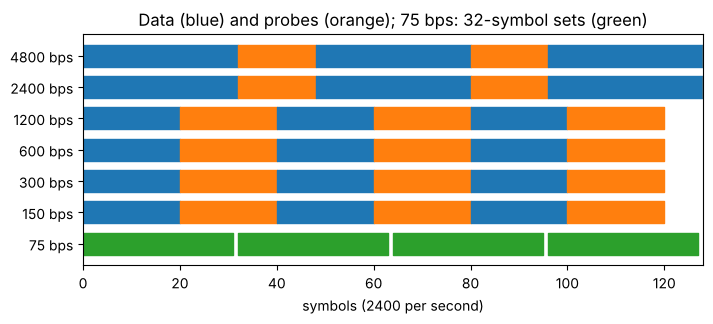

In [9]:
order = [mode(4800), *[mode(r, "short") for r in (2400, 1200, 600, 300, 150, 75)]]
fig, ax = plt.subplots(figsize=(8, 3))
for row, m in enumerate(order):
    if m.is_75bps:
        for k in range(4):
            ax.broken_barh([(32 * k, 31)], (row - 0.35, 0.7), color="C2")
    else:
        u, k_ = m.unknown_per_frame, m.known_per_frame
        for f_ in range(3):
            start = f_ * (u + k_)
            ax.broken_barh([(start, u)], (row - 0.35, 0.7), color="C0")
            ax.broken_barh([(start + u, k_)], (row - 0.35, 0.7), color="C1")
ax.set_yticks(range(len(order)), [f"{m.rate} bps" for m in order])
ax.invert_yaxis()
ax.set_xlim(0, 128)
ax.set_xlabel("symbols (2400 per second)")
ax.set_title("Data (blue) and probes (orange); 75 bps: 32-symbol sets (green)")
plt.show()

### 75 bps: patterns instead of phases

At 75 bps each two-bit channel symbol is sent as one of four 32-symbol patterns of the
phases 0 and 4 (Table X), repeated Walsh-like codes that are mutually orthogonal: the
receiver correlates against all four and picks the strongest, which works far below the
SNR where single symbols could be read. Every 45th set (360th with long interleave) uses
an *exceptional* pattern, orthogonal to the normal ones, which marks the interleaver
position (INT-010).

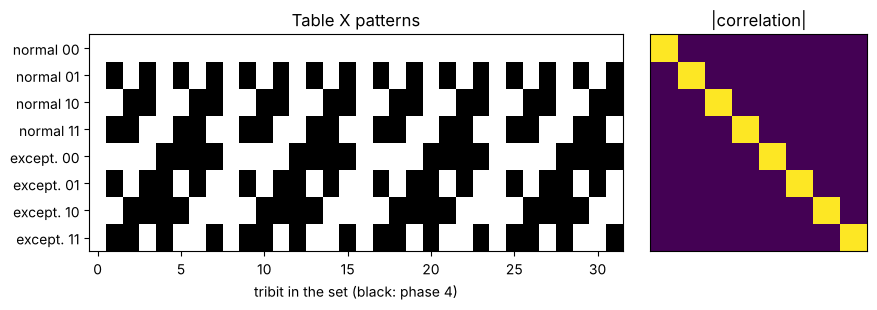

largest correlation between two different patterns: 0.0


In [10]:
patterns = [T.TABLE_X_NORMAL[v] for v in range(4)] + [T.TABLE_X_EXCEPTIONAL[v] for v in range(4)]
phasors = np.exp(1j * np.pi / 4 * np.array(patterns))
corr = np.abs(phasors @ phasors.conj().T) / 32
names = [f"normal {v:02b}" for v in range(4)] + [f"except. {v:02b}" for v in range(4)]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].imshow(np.array(patterns) / 4, cmap="Greys", aspect="auto")
ax[0].set_yticks(range(8), names)
ax[0].set_xlabel("tribit in the set (black: phase 4)")
ax[0].set_title("Table X patterns")
ax[1].imshow(corr, cmap="viridis", vmin=0, vmax=1)
ax[1].set_xticks([])
ax[1].set_yticks([])
ax[1].set_title("|correlation|")
plt.tight_layout()
plt.show()
print(
    "largest correlation between two different patterns:", round(float(np.max(corr - np.eye(8))), 3)
)

## 5. The preamble (§5.3.2.3.7.2)

The transmission starts with 3 (short or zero interleave) or 24 (long) segments of 15
channel symbols, each sent as 32 scrambled tribits. Nine fixed symbols open every segment,
then D1 and D2 (the mode, Table XI) and a count of segments remaining (INT-001). The
receiver uses them to find the signal, its carrier and timing, and the mode.

In [11]:
print("one segment's channel symbols:", symbols.preamble_channel_symbols(MODE)[:15])
print("D1, D2 =", MODE.d1_d2, "; count digits for 2 segments left:", symbols.count_symbols(2))

one segment's channel symbols: [0 1 3 0 1 3 1 2 0 6 4 4 4 6 0]
D1, D2 = (6, 4) ; count digits for 2 segments left: (4, 4, 6)


Each row below is one segment, as channel symbols (each sent as 32 tribits, Table XIII):
the fixed prefix that the receiver searches for, then D1 and D2, then the count of
segments still to come, written in three base-4 digits plus 4 (INT-001), then a zero. The
count runs down to 0, so a receiver that catches the preamble late still knows where the
data starts.

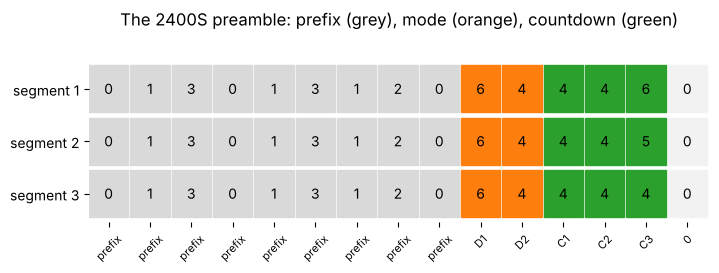

In [12]:
segments_ch = symbols.preamble_channel_symbols(MODE).reshape(-1, 15)
roles = ["prefix"] * 9 + ["D1", "D2", "C1", "C2", "C3", "0"]
colours = {
    "prefix": "0.85",
    "D1": "C1",
    "D2": "C1",
    "C1": "C2",
    "C2": "C2",
    "C3": "C2",
    "0": "0.95",
}
fig, ax = plt.subplots(figsize=(8, 0.55 * len(segments_ch) + 0.8))
for r, seg in enumerate(segments_ch):
    for c, (value, role) in enumerate(zip(seg, roles, strict=True)):
        ax.add_patch(plt.Rectangle((c, r), 0.95, 0.9, color=colours[role]))
        ax.text(c + 0.47, r + 0.45, str(value), ha="center", va="center")
ax.set_xlim(0, 15)
ax.set_ylim(len(segments_ch), -0.6)
ax.set_xticks(np.arange(15) + 0.47, roles, fontsize=8, rotation=45)
ax.set_yticks(
    np.arange(len(segments_ch)) + 0.45, [f"segment {k + 1}" for k in range(len(segments_ch))]
)
ax.set_title(f"The {MODE} preamble: prefix (grey), mode (orange), countdown (green)")
for side in ("top", "right", "bottom", "left"):
    ax.spines[side].set_visible(False)
plt.show()

## 6. Modulation (§5.3.2.3.9)

Each tribit k is the phasor e^(jπk/4) (INT-021), shaped by a root-raised-cosine filter
(α = 0.25, INT-015) and moved to the 1800-Hz carrier. The output is complex baseband at
9600 samples/s whose real part is the audio. The spectrum fills 300–3300 Hz.

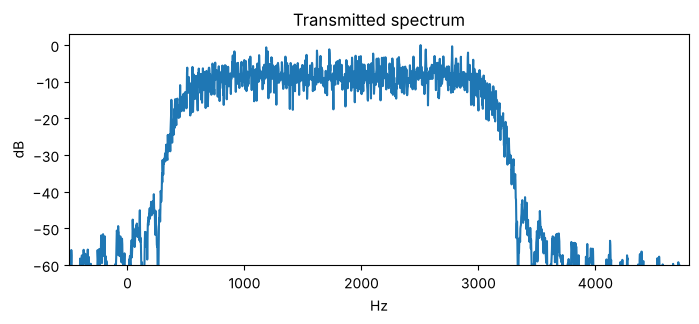

RRC filter taps at 4 samples/symbol: 65


In [13]:
x = modulate(tx)
f = np.fft.fftshift(np.fft.fftfreq(4096, 1 / 9600))
segments = x[: x.size // 4096 * 4096].reshape(-1, 4096) * np.hanning(4096)
psd = np.fft.fftshift(np.mean(np.abs(np.fft.fft(segments, axis=1)) ** 2, axis=0))
plt.plot(f, 10 * np.log10(psd / psd.max()))
plt.xlim(-500, 4800)
plt.ylim(-60, 3)
plt.xlabel("Hz")
plt.ylabel("dB")
plt.title("Transmitted spectrum")
plt.show()
print("RRC filter taps at 4 samples/symbol:", rrc_taps(4).size)

### The pulse, and why the receiver samples where it does

The root-raised-cosine pulse is not itself free of inter-symbol interference: it crosses
zero near, not at, the neighbouring symbol times. The receiver filters with the same pulse
(a matched filter), and the two together make a raised cosine, which is exactly zero at
every other symbol's sampling instant. The eye diagram of the in-phase part shows it: the
traces of many symbols pass through a few clean points at the sampling instant (the
8-PSK values cos(k 45°)), and spread out in between.

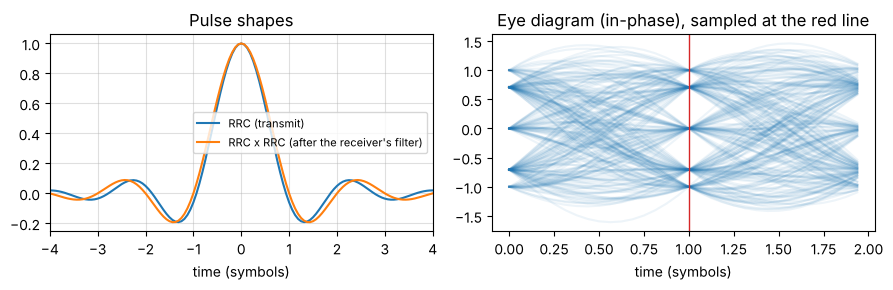

In [14]:
sps = 16
h = rrc_taps(sps)
t_sym = (np.arange(h.size) - h.size // 2) / sps
rc = np.convolve(h, h)
t_rc = (np.arange(rc.size) - rc.size // 2) / sps
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(t_sym, h / h.max(), label="RRC (transmit)")
ax[0].plot(t_rc, rc / rc.max(), label="RRC x RRC (after the receiver's filter)")
ax[0].set_xticks(range(-4, 5))
ax[0].set_xlim(-4, 4)
ax[0].grid(True, alpha=0.4)
ax[0].set_xlabel("time (symbols)")
ax[0].legend(fontsize=8)
ax[0].set_title("Pulse shapes")
base = modulate(tx[n_pre : n_pre + 600], sample_rate=sps * 2400, carrier_hz=0)
matched = np.convolve(base, h)
delay = h.size - 1  # transmit and receive filters, each (h.size - 1) / 2
eye = matched[delay + 20 * sps :][: 500 * sps]
eye = eye[: eye.size // (2 * sps) * (2 * sps)].reshape(-1, 2 * sps)
scale = np.median(np.abs(matched[delay::sps][20:500]))
ax[1].plot(np.arange(2 * sps) / sps, (eye.real / scale).T, color="C0", alpha=0.08)
ax[1].axvline(1, color="C3", lw=1)
ax[1].set_xlabel("time (symbols)")
ax[1].set_title("Eye diagram (in-phase), sampled at the red line")
plt.tight_layout()
plt.show()

## 7. An HF channel (Appendix E)

The Watterson model: two paths 2 ms apart, each fading with a 1-Hz Gaussian Doppler
spectrum, plus noise at 18 dB in 3 kHz. That is one row of Table XVI, the conditions the
standard requires 2400 bps to survive with a bit error rate of at most 1e-5.

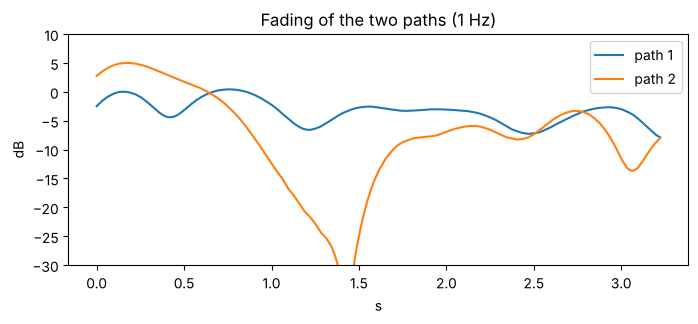

In [15]:
lead = np.zeros(4000, complex)
x_in = np.concatenate([lead, x, np.zeros(9600, complex)])
channel = WattersonChannel(ChannelSpec(2, 2.0, 1.0, 18.0), seed=7)
y = channel.process(x_in)
t = np.arange(x_in.size) / 9600
# The same seed gives the same fading; read it from a noiseless twin of the channel.
gains = WattersonChannel(ChannelSpec(2, 2.0, 1.0, None), seed=7)
g0, g1 = gains._fading[0].next(x_in.size), gains._fading[1].next(x_in.size)
plt.plot(t, 20 * np.log10(np.abs(g0) + 1e-9), label="path 1")
plt.plot(t, 20 * np.log10(np.abs(g1) + 1e-9), label="path 2")
plt.ylim(-30, 10)
plt.xlabel("s")
plt.ylabel("dB")
plt.legend()
plt.title("Fading of the two paths (1 Hz)")
plt.show()

## 8. Finding the preamble

The receiver searches ±400 Hz around 1800 Hz for the nine fixed slots of a preamble
segment, then reads D1, D2 and the count, and checks the count against the next segments
(§5.3.2.3.7.2, INT-001). Here it finds the first segment, with the carrier offset and the
mode.

In [16]:
search = PreambleSearch()
detection = search.process(y) or search.flush()
print(
    detection.mode,
    "at",
    round(detection.segment_start / 9600, 3),
    "s;",
    "carrier",
    round(detection.carrier_hz, 2),
    "Hz; segments left",
    detection.count,
)

2400S at 0.419 s; carrier 1800.16 Hz; segments left 2


## 9. Equalisation

At every probe the receiver estimates the channel (both paths, with their fading), and
computes a decision-feedback equaliser from it. The plot shows the received symbols
before and after: the raw samples are smeared by multipath and fading; the equalised
ones sit on the eight phases. (Shown after descrambling, so they are the MGD symbols.)

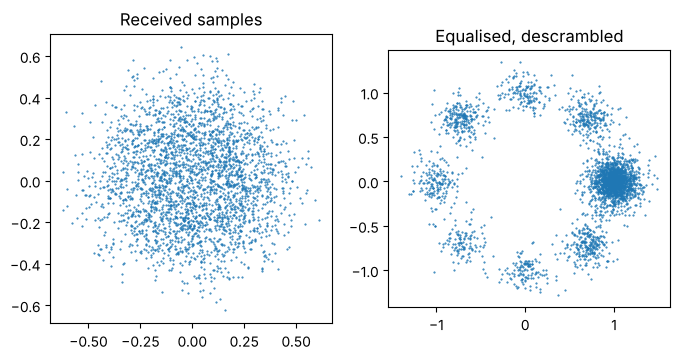

In [17]:
start = int(detection.segment_start) - 8
demod = EqualizingDemodulator(detection.mode, detection, start_index=start)
z, var = demod.process(y[start:])
z2, var2 = demod.finish()
z, var = np.concatenate([z, z2]), np.concatenate([var, var2])
n_data = tx.size - symbols.preamble_tribits(MODE).size  # what followed is noise, not data
z, var = z[:n_data], var[:n_data]
clean = z * np.conj(np.exp(1j * np.pi / 4 * scrambler.data_sequence(0, z.size)))
raw = y[start + 4 * symbols.preamble_tribits(MODE).size :][::4][: z.size]
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].plot(raw.real, raw.imag, ".", markersize=1)
ax[0].set_title("Received samples")
ax[1].plot(clean.real, clean.imag, ".", markersize=1)
ax[1].set_title("Equalised, descrambled")
for a in ax:
    a.set_aspect("equal")
plt.show()

## 10. Decoding

The equalised symbols go back through the chain in reverse: descramble, soft-demap (each
symbol's bits get a reliability, weighted by the equaliser's error variance), deinterleave,
Viterbi-decode. The end-of-message pattern (§5.3.2.3.1, INT-018) says where the user data
stopped.

In [18]:
decoder, eom = DataDecoder(detection.mode), EomDetector()
bits = eom.process(decoder.process(z, var))
bits = np.concatenate([bits, eom.process(decoder.finish()), eom.finish()])
received = bits_to_bytes(bits[: bits.size // 8 * 8])
print("EOM found:", eom.found, "; SNR on the probes:", round(decoder.snr_db, 1), "dB")
print("bytes:", len(received), "; identical to the message:", received == MESSAGE)
print(received[:58].decode())

EOM found: True ; SNR on the probes: 14.0 dB
bytes: 224 ; identical to the message: True
THE QUICK BROWN FOX JUMPS OVER THE LAZY DOG 0123456789
TH


## 11. What the coding buys

Each rate puts the same 4800 channel bits a second on the air (Table XV), and spends the
difference between that and its user rate on redundancy: 4800 bps sends none, 2400 bps
the rate-1/2 code, 600-150 bps the code repeated, 75 bps the code inside 32-symbol sets.
On a steady channel with noise alone (no fading), simulating just the symbols and the
decoder shows what that redundancy buys: each halving of the rate lets the link work
several dB lower in SNR. (The fading channel, where the interleaver matters too, is in
the channel notebook.)

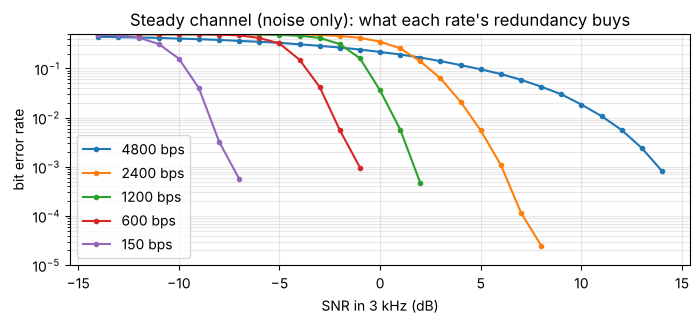

In [19]:
rng = np.random.default_rng(11)
n_bits = 8_000 if QUICK else 120_000
snrs = np.arange(-14, 15, 2.0 if QUICK else 1.0)


def ber_awgn(m, snr_db):
    bits = rng.integers(0, 2, n_bits if m.rate >= 1200 else n_bits // 4).astype(np.uint8)
    data = transmit(bits, m)[m.preamble_symbols :]
    n0 = 1 / (10 ** (snr_db / 10) * 3000 / T.SYMBOL_RATE)  # Es/N0 from SNR in 3 kHz
    noise = np.sqrt(n0 / 2) * (rng.standard_normal(data.size) + 1j * rng.standard_normal(data.size))
    decoder = DataDecoder(m)
    z = np.exp(1j * np.pi / 4 * data) + noise
    out = np.concatenate([decoder.process(z, np.full(z.size, n0)), decoder.finish()])
    return np.mean(out[: bits.size] != bits), bits.size


for m in (
    mode(4800),
    mode(2400, "short"),
    mode(1200, "short"),
    mode(600, "short"),
    mode(150, "short"),
):
    points = [(s, *ber_awgn(m, s)) for s in snrs]
    s_, b_, n_ = zip(*[(s, b, n) for s, b, n in points if b > 0], strict=False) or ((), (), ())
    plt.semilogy(s_, b_, "o-", markersize=3, label=f"{m.rate} bps")
plt.ylim(1e-5, 0.5)
plt.xlabel("SNR in 3 kHz (dB)")
plt.ylabel("bit error rate")
plt.title("Steady channel (noise only): what each rate's redundancy buys")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

## Where to go next

- `docs/channel.ipynb`: the HF channel itself, and why different conditions call for
  different modes.
- `docs/playground.ipynb`: what a link layer over 110 has to live with (experiments).
- `docs/CONFORMANCE.md`: every Table XVI row, run for a million bits.
- `docs/PERFORMANCE.md`: how the receiver was designed and measured, including what did
  not work.
- `docs/SPEC_NOTES.md`: every place where the standard is ambiguous, and what we chose.
- `docs/VALIDATION.md`: the comparison with recordings of real modems.